# Importing, libraries

In [4]:
import pandas as pd
import spacy
from tqdm import tqdm
import swifter
import matplotlib.pyplot as plt
from langchain_community.llms import Ollama
from sklearn.cluster import KMeans
import numpy as np
import re
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity
import umap
from sklearn.cluster import KMeans
from yake import KeywordExtractor
from langchain_community.llms import Ollama


# Stage-1: Data Imports and Pre-Processing 

In [5]:
df = pd.read_excel("new_mape.xlsx")

In [6]:
df.columns

Index(['doc_id', 'doc_source', 'doc_box', 'doc_number', 'doc_year',
       'doc_text'],
      dtype='object')

In [7]:
df.shape

(180180, 6)

In [12]:
nlp = spacy.load("pt_core_news_sm")
tqdm.pandas()

def count_words(text):
    doc = nlp(text)
    return len([token for token in doc if token.is_alpha])

df['doctext_word_count'] = df['doc_text'].swifter.apply(count_words)


Pandas Apply:   0%|          | 0/180180 [00:00<?, ?it/s]

In [16]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
doc_id,180180.0,1.290655e+06,76349.103844,1137546.0,1225446.75,1290101.5,1335146.25,1473041.0
doc_year,180172.0,1.769949e+03,43.108156,1538.0,1744.00,1778.0,1803.00,1900.0
doctext_word_count,180180.0,4.568879e+01,28.608967,1.0,30.00,39.0,53.00,933.0


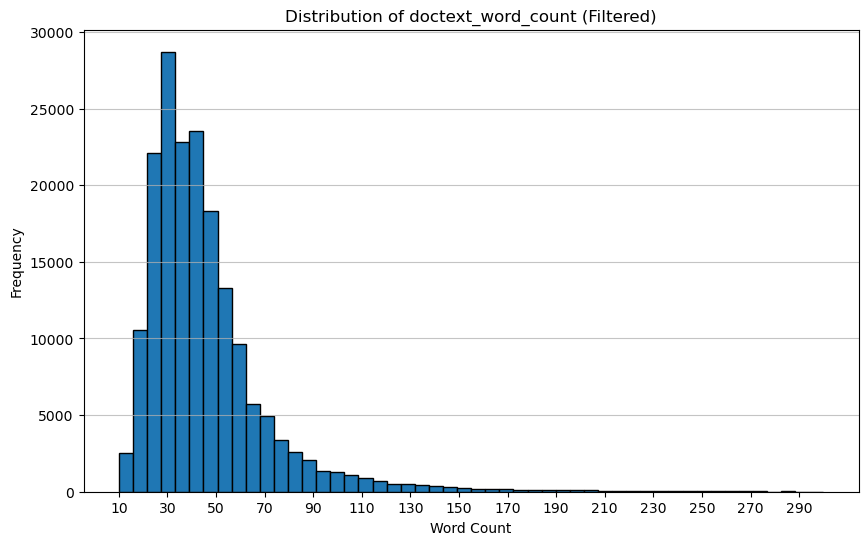

In [20]:
import matplotlib.pyplot as plt
import numpy as np

filtered_data = df[(df['doctext_word_count'] >= 10) & (df['doctext_word_count'] <= 300)]

# Plot the histogram
plt.figure(figsize=(10, 6))
plt.hist(filtered_data['doctext_word_count'], bins=50, edgecolor='black')
plt.title('Distribution of doctext_word_count (Filtered)')
plt.xlabel('Word Count')
plt.ylabel('Frequency')

xticks = np.arange(10, 301, 20)
plt.xticks(xticks)

plt.grid(axis='y', alpha=0.75)
plt.show()


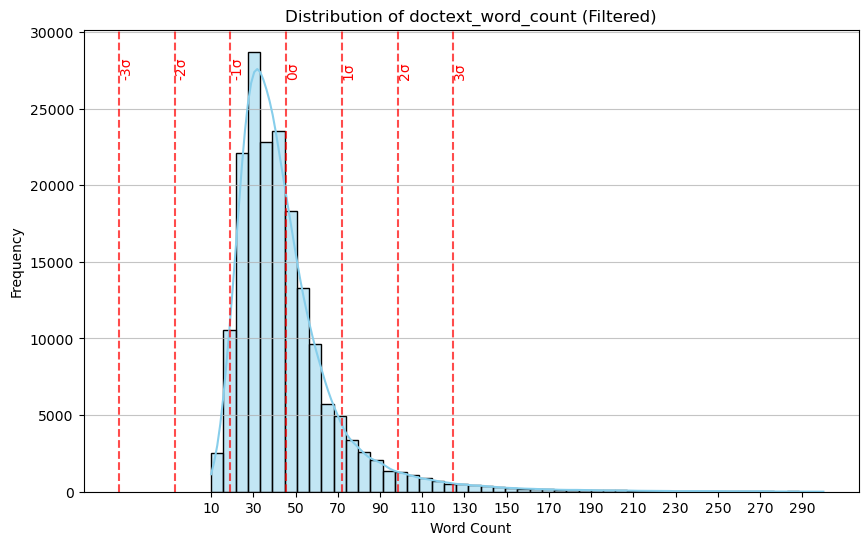

In [24]:
mean = filtered_data['doctext_word_count'].mean()
std = filtered_data['doctext_word_count'].std()

plt.figure(figsize=(10, 6))
sns.histplot(filtered_data['doctext_word_count'], bins=50, kde=True, edgecolor='black', color='skyblue')
plt.title('Distribution of doctext_word_count (Filtered)')
plt.xlabel('Word Count')
plt.ylabel('Frequency')

for sigma in [-3, -2, -1, 0, 1, 2, 3]:
    plt.axvline(mean + sigma * std, color='red', linestyle='--', alpha=0.7)
    plt.text(mean + sigma * std, plt.ylim()[1] * 0.9, f'{sigma}σ', color='red', fontsize=10, rotation=90)

xticks = np.arange(10, 301, 20)
plt.xticks(xticks)

plt.grid(axis='y', alpha=0.75)
plt.show()


In [28]:
 df[(df['doctext_word_count'] >= 10) & (df['doctext_word_count'] <= 150)]["doc_text"]


0         INFORMAÇÃO do [Conselho Ultramarino] sobre os ...
1         CONSULTA do Conselho Ultramarino ao rei D. Ped...
2         CONSULTA do Conselho Ultramarino ao rei [D. Pe...
3         CARTA dos oficiais da Câmara da vila de Alagoa...
4         PROPOSTA (cópia) do [mestre de campo] Domingos...
                                ...                        
180175    Ofício do Governador de Sergipe,  Carlos César...
180176    Carta Patente pela qual Carlos César Burlamarq...
180177    Requerimento de José Alves de Campos, Capitão ...
180178    Consulta do Conselho Ultramarino sobre o motiv...
180179    Carta dos Oficiais da Câmara de Vila Nova Real...
Name: doc_text, Length: 177698, dtype: object

In [ ]:
 df[(df['doctext_word_count'] >= 10) & (df['doctext_word_count'] <= 150)].reset_index(drop=True).to_csv("modified_letters.csv", index=False)

# Stage-2: Topic Generation using llm

In [ ]:
def load_dataset_with_progress(file_path="modified_letters.csv"):
    df = pd.read_csv(file_path)
    df['Main_Topic'] = None  
    print(f"Starting fresh with the dataset. Loaded '{file_path}'.")
    return df

def load_llm():
    llm = Ollama(model="llama3:latest")  
    return llm

def extract_topic_from_letter(llm, text):
    prompt = (
        f"Given the following historical letter, generate a concise topic for cataloging purposes. "
        f"Ignore any references to dates, people’s names, or locations. "
        f"Focus only on the main topic of the letter. Keep it short and focused on the subject discussed:\n\n"
        f"{text}\n\n"
        f"Main Topic:"
    )
    topic = llm.predict(prompt).strip()
    
    # topic = re.sub(r'\b\d{4}\b', '', topic)  
    return topic

def process_and_save(df, file_path="letters_with_clustered_topics.csv"):
    llm = load_llm()

    for i, row in df.iterrows():
        if pd.isna(row['Main_Topic']):  
            letter_text = row['doc_text']
            topic = extract_topic_from_letter(llm, letter_text)
            df.at[i, 'Main_Topic'] = topic  

            print(f"Letter {i+1}:\n{letter_text}")
            print(f"Concise Topic: {topic}\n")

            df.to_csv(file_path, index=False)
            print(f"Progress saved to '{file_path}'.")

    return df

def main():
    df = load_dataset_with_progress()

    df_with_topics = process_and_save(df)

    df_with_topics.to_csv("letters_with_topics_final.csv", index=False)

main()


# Stage-3: 3.1 Embedding Generation-(Doc-Text and LLM Topics)

In [31]:
df_after_llm = pd.read_excel("31Novfg.xlsx", 
                             usecols=["doc_text", "doc_year","LLM Suggested Topic","Modern_Name"])
df_after_llm.columns

Index(['doc_text', 'doc_year', 'LLM Suggested Topic', 'Modern_Name'], dtype='object')

In [ ]:

model = SentenceTransformer('sentence-transformers/paraphrase-xlm-r-multilingual-v1')

doc_text_embeddings = model.encode(df_after_llm['doc_text'].tolist(), show_progress_bar=True)

topic_embeddings = model.encode(df_after_llm['LLM Suggested Topic'].tolist(), show_progress_bar=True)

np.save("doc_text_embeddings.npy", doc_text_embeddings)
np.save("topic_embeddings.npy", topic_embeddings)



# Stage-3: 3.2 Topic Validations 

In [ ]:
doc_text_embeddings = np.load("doc_text_embeddings.npy")
topic_embeddings = np.load("topic_embeddings.npy")
cosine_similarities = [
    cosine_similarity([doc_text_embeddings[i]], [topic_embeddings[i]])[0][0]
    for i in range(len(doc_text_embeddings))
]

df_after_llm['Cosine_Similarity'] = cosine_similarities


# Stage-3: 3.3 Dim-Reduction UMAP

In [ ]:
doc_text_embeddings = np.load("doc_text_embeddings.npy")
topic_embeddings = np.load("topic_embeddings.npy")

combined_embeddings = np.hstack((doc_text_embeddings, topic_embeddings))

reducer = umap.UMAP(n_components=50, random_state=42)
umap_embeddings = reducer.fit_transform(combined_embeddings)

np.save("umap_50d_embeddings.npy", umap_embeddings)

df_after_llm_umap = pd.DataFrame(umap_embeddings, columns=[f"UMAP_{i+1}" for i in range(50)])
df_final = pd.concat([df_after_llm, df_after_llm_umap], axis=1)
df_final.to_csv("final_dataset_with_umap.csv", index=False)

##############################################################################
reducer = umap.UMAP(n_components=2, random_state=42)
embeddings_2d = reducer.fit_transform(combined_embeddings)

plt.figure(figsize=(10, 6))
plt.scatter(embeddings_2d[:, 0], embeddings_2d[:, 1], s=50, c='blue', alpha=0.7)
for i, (x, y) in enumerate(embeddings_2d):
    plt.text(x, y, str(i+1), fontsize=9, ha='right', va='bottom')

plt.title("2D Visualization of First 22 Combined Embeddings")
plt.xlabel("UMAP Dimension 1")
plt.ylabel("UMAP Dimension 2")
plt.grid(True)
plt.show()


# Stage-4: 4.1 Clustering 

In [ ]:

def perform_clustering(umap_embeddings, num_clusters=100):
    kmeans = KMeans(n_clusters=num_clusters, random_state=42)
    cluster_labels = kmeans.fit_predict(umap_embeddings)
    return cluster_labels

cluster_labels = perform_clustering(umap_embeddings, num_clusters=100)


# Stage-4: 4.2 Clusters labelling process

In [ ]:
def extract_keywords_per_cluster(df, cluster_labels, num_clusters=100):
    df['Cluster_Label'] = cluster_labels
    keyword_extractor = KeywordExtractor(lan="en", n=3, top=5)
    cluster_keywords = {}
    for cluster in range(num_clusters):
        cluster_texts = df[df['Cluster_Label'] == cluster]['doc_text'].tolist()
        combined_text = " ".join(cluster_texts)
        keywords = keyword_extractor.extract_keywords(combined_text)
        cluster_keywords[cluster] = [kw[0] for kw in keywords]
    return cluster_keywords

def label_clusters_with_llm(cluster_keywords, llm_model="llama3:latest"):
    llm = Ollama(model=llm_model)
    cluster_labels = {}
    for cluster, keywords in cluster_keywords.items():
        prompt = f"Given these keywords: {', '.join(keywords)}, provide a concise label for this cluster, without any extra details."
        cluster_labels[cluster] = llm.predict(prompt).strip()
    return cluster_labels

def collapse_clusters(cluster_labels, llm_model="llama3:latest"):
    llm = Ollama(model=llm_model)
    labels = list(cluster_labels.values())
    prompt = f"Group these cluster labels into broader categories: {', '.join(labels)}."
    final_groups = llm.predict(prompt).strip()
    return final_groups


In [ ]:
cluster_keywords = extract_keywords_per_cluster(df, cluster_labels, num_clusters=100)
cluster_labels_dict = label_clusters_with_llm(cluster_keywords, llm_model="llama3:latest")
df['Cluster_Label_Description'] = df['Cluster_Label'].map(cluster_labels_dict)


In [ ]:
final_groups = collapse_clusters(cluster_labels_dict, llm_model="llama3:latest")
